# Estudio y discusión del notebook 29

Para esta actualización, empieza por las dos notas siguientes: qué verificamos del diseño y qué permite concluir la comparación con rollout. Después vuelve a la ruta de estudio del argumento $\log G$.

## Retomar después de la pausa: 40 minutos

1. Diez minutos: bloque 1. Dibujar ABC, ABD, ACD y reconstruir los conteos si solo C y D están infectados. Explicar qué se ahorra y por qué el valor esperado es 2. Después distinguir este plan del óptimo laminar 1.75.
2. Diez minutos: bloques 2 y 3. Leer la malla y distinguir una separación observada de la cota de información.
3. Diez minutos: bloque 4. Explicar qué mejoró en los diseños y por qué mantener bloques pequeños limita el experimento.
4. Diez minutos: bloques 5 y 6. Separar la comparación de heurísticas de la pregunta general/laminar y defender el siguiente experimento.

No hace falta dominar antes todo el paper de Nic. Para la discusión sí hace falta distinguir un ejemplo, una evidencia finita y una afirmación sobre todos los tamaños.

## Guion de cinco minutos

«El diseño pequeño ya ahorra una prueba y supera al óptimo laminar. Para estudiar cuánto puede crecer esa ventaja, necesitamos una familia de matrices y una cota para toda política laminar. Nuestra malla localiza separaciones, pero mantiene una población tan pequeña que no puede mostrar crecimiento logarítmico.»

El material anterior se conserva abajo como consulta. Los bloques binario/laminar y greedy/rollout siguen siendo encargos del plan semanal, aunque ahora el pase principal se centra en la propuesta de Francisco.


## Actualización: qué confirmó la auditoría del diseño

Frase para presentar: «Verificamos el valor del diseño, y encontramos que aumentar el límite $G$ ya no amplía las pruebas que puede elegir».

Se recorrieron los $65\,536$ perfiles equiprobables por objetivo. En cada hoja se acredita solo a quienes están sanos en todos los perfiles compatibles. El evaluador usa sumas enteras y fracciones; no llama al juez original ni usa el valor interno del optimizador. Se reutiliza el generador del diseño, por lo que esto verifica su valor, no vuelve a optimizar toda la clase general.

Los resultados coinciden en los seis objetivos. Para $B=4$, los valores son $11/4$, $107/32$, $3459/1024$ y $3459/1024$ en $G=2,4,8,16$. Para $B=8$, ambos valores son $6769/1024$. Los árboles completos quedaron guardados junto a `loop1_audit.json`.

¿Por qué la curva plana no decide la conjetura? El diseño abre bloques de hasta seis personas, usa pools de hasta cinco y nunca combina bloques. Al pasar de $G=8$ a $G=16$ se conserva exactamente la familia disponible. Además, con $n=16$ hay ocho sanos en promedio: con $B=8$, cualquier política cumple $V/B\le1$.

¿Es buena dirección permitir grupos entre bloques? Sí, como experimento para saber si esa restricción cuesta utilidad. No sabemos si es la única manera de mejorar: ampliar los bloques también cambia la familia. Un piloto debe separar ambos cambios. Para explorar $\log G$, los bloques o componentes usados deberán crecer con $G$, y también la población disponible.

Piloto propuesto: mantener primero los seis objetivos y el diseño actual como candidato de referencia; añadir por separado pools entre bloques o bloques mayores. Mismo evaluador, límites de tiempo y memoria fijados antes de correr. Guardar el primer árbol que mejore, su decisión distinta y el tamaño real de los pools. Validarlo independientemente y repetir en parámetros nuevos antes de una búsqueda larga. Una mejora finita no prueba la cota laminar ni crecimiento asintótico.

## Actualización: qué compara realmente el experimento de heurísticas

Frase para presentar: «La búsqueda encontró una regla casi exacta en los casos usados para seleccionarla. En $n=50$, todavía no vemos que compense su costo frente a rollout».

La regla conservada tiene SHA `cc6dae29d4`. En las 125 celdas de selección alcanza el óptimo en 124 y su mayor pérdida es 0.281%, en $n=6,B=3,G=4,q=0.7$. La batería se reutilizó durante la búsqueda: ese número no es una garantía para casos nuevos. Tampoco debe compararse directamente con la pérdida anterior del 5.26% de rollout: aquella medición usa otra malla y una jerarquía fija que permite menos grupos. Primero hay que igualar casos y acciones.

En $n=50$, $p_i$ se sortea uniforme en $[0,1]$, $q_i=1-p_i$ y $u_i$ uniforme en $\{1,2,3\}$. Se ordena por $q_i u_i$ y se fijan bloques de tamaño $G$. Cada decisión considera los bloques ya tocados y los tres intactos con mayor ganancia inmediata. Las tres reglas comparten esta restricción; no se compara con el óptimo laminar.

Rollout evalúa una primera acción seguida de greedy hasta agotar el presupuesto, y reconsidera tras observar el resultado real. La regla nueva mira hasta cuatro pruebas: en el primer nivel interno conserva los cuatro mejores candidatos inmediatos; en los siguientes, el mejor. Además añade el mejor de cada tamaño cuando quedan varios niveles. La última evaluación es de ganancia inmediata, no una continuación greedy hasta el final. La versión de $n=50$ reproduce esta regla con inferencia exacta por bloque.

La simulación usa los mismos perfiles para las tres políticas: 48 instancias × 24 sorteos en $G=3$ y 24 × 12 en $G=5$. El porcentaje es la diferencia media de utilidad dividida entre la media de la referencia. El error estándar se calcula sobre las diferencias pareadas por instancia, no tratando cada sorteo como una instancia nueva. Los segmentos son intervalos t aproximados del 95% para esa diferencia, escalados por la media observada de rollout; no son intervalos exactos para un cociente.

La ventaja adicional de la regla es 0.16% (intervalo aproximado -0.11% a 0.43%) y 0.34% (-1.01% a 1.69%). Que ambos incluyan cero significa que no se distingue una ventaja con esta precisión; no prueba igualdad.

Los tiempos son el total medio por instancia para todos sus sorteos, reutilizando cachés: 4.8 s frente a 18.3 s en $G=3$, y 95.0 s frente a 918.5 s en $G=5$. No son segundos por decisión, y los dos valores de $G$ usan distinto número de sorteos. La validación a $10^{-6}$ del harness en casos de un bloque es un control de implementación; no demuestra optimalidad ni valida todas las políticas laminares.

¿Qué haría después? Mantener rollout como referencia y reservar instancias nuevas antes de ajustar otra regla. Comparar ambos métodos con las mismas acciones y un límite común de tiempo, reportando utilidad y pérdidas además de la media. Solo después decidir si interesa mayor profundidad, diversidad de tamaños o cambiar la partición. Este frente mejora decisiones dentro de una clase; no resuelve la pregunta general/laminar.

## Cómo explicar el control de 4/3

Antes de cualquier prueba, los 16 perfiles de cuatro personas son equiprobables. El historial ABC=1 deja seis: tres ubicaciones posibles del infectado en ABC, cada una combinada con los dos estados de D. Por eso ocurre con probabilidad $6/16=3/8$.

Condicionados a ese historial, A es el infectado en un tercio de los casos. Si al probar A resulta infectado, B y C son sanos: cobramos 2. En los otros dos tercios A resulta sano: cobramos 1; sigue sin saberse cuál de B y C es el infectado. D sigue desconocido en ambos casos.

El cálculo $\frac23\cdot1+\frac13\cdot2=\frac43$ es utilidad adicional de esa última prueba, condicionada al historial. Su contribución al promedio desde el inicio sería $\frac38\cdot\frac43=\frac12$; faltan las otras ramas de ABC. No es una política completa de una prueba que obtenga 4/3 desde el prior.

Respuesta provisional para discutir: el argumento «como mucho uno por prueba en cada historial» falla. Una prueba global podría asignar crédito tanto a sanos ya identificados como a información todavía pendiente de aprovechar. El ejemplo sugiere qué debe contabilizar; no hemos construido ni demostrado ese potencial.

Pregunta a Francisco: «¿Tu cota laminar controla una cantidad acumulada que incluya la información pendiente? Este historial nos da 4/3 con una sola prueba restante».

La enumeración exacta de los 16 perfiles y el solver por perfiles coinciden. Código reproducible: `augmented/notebooks/enfocar_log_g_29.py`; evidencia en `results/sesion_2026-10-16/enfoque_log_G/evidencia.json`.

## Contraejemplo: comprobación a mano

$q_A=19/20$, $q_B=q_C=4/5$, $B=G=2$, $u_i=1$. Los tres modelos tienen los mismos recursos.

AB negativo tiene probabilidad $0.95\times0.8=0.76$. C sigue sano con probabilidad 0.8. La contribución de esa rama es $0.76(2+0.8)=2.128$ en las dos políticas.

AB positivo y AC negativo significa exactamente A sano, B infectado y C sano. Su probabilidad conjunta es $0.95(0.2)(0.8)=0.152$. Es la multiplicación más sencilla: dos sanos acreditados por $0.152$ de probabilidad. Así, la política binaria vale $2.128+2(0.152)=2.432$.

Para dibujar el árbol con probabilidades condicionales: $P(AC^-\mid AB^+)=0.152/0.24=19/30$. A queda sano con probabilidad $0.19/0.24=19/24$, y C sigue independiente con probabilidad $4/5$. Por eso probar AC sigue teniendo sentido.

El laminar observa $R=1$ con probabilidad $0.95(0.2)+0.05(0.8)=0.23$ y puede asegurar un sano probando A. Con $R=2$, probabilidad $0.01$, prueba C y cobra 0.8 en promedio. Total: $2.128+0.23+0.008=2.366$.

## ¿Cómo sabemos que no hay una política laminar mejor?

Hay seis primeras pruebas. Enumerar todas sus continuaciones legales da: A → 2.23; B o C → 2.32; AB o AC → 2.366; BC → 2.246. Su máximo es 2.366. Este cálculo directo coincide con el Bellman sobre perfiles y con el solver de átomos residuales.

Incluso sin certificar el óptimo binario, una política binaria de valor 2.432 ya separaría las clases del óptimo laminar 2.366. Además, dos solvers binarios coinciden en que esa política es óptima.

No atribuimos esta separación a un beneficio de tener menos información. El general siempre puede imitar al binario y aquí obtiene 2.448. Lo que cuesta es restringir las pruebas permitidas.

## Una región, además de un punto

$n=3$, $B=G=2$, $u_i=1$, $q_A=0.95$, $q_B=q_C=t$. Se evaluaron exactamente $t=0.05,0.06,\ldots,0.99$.

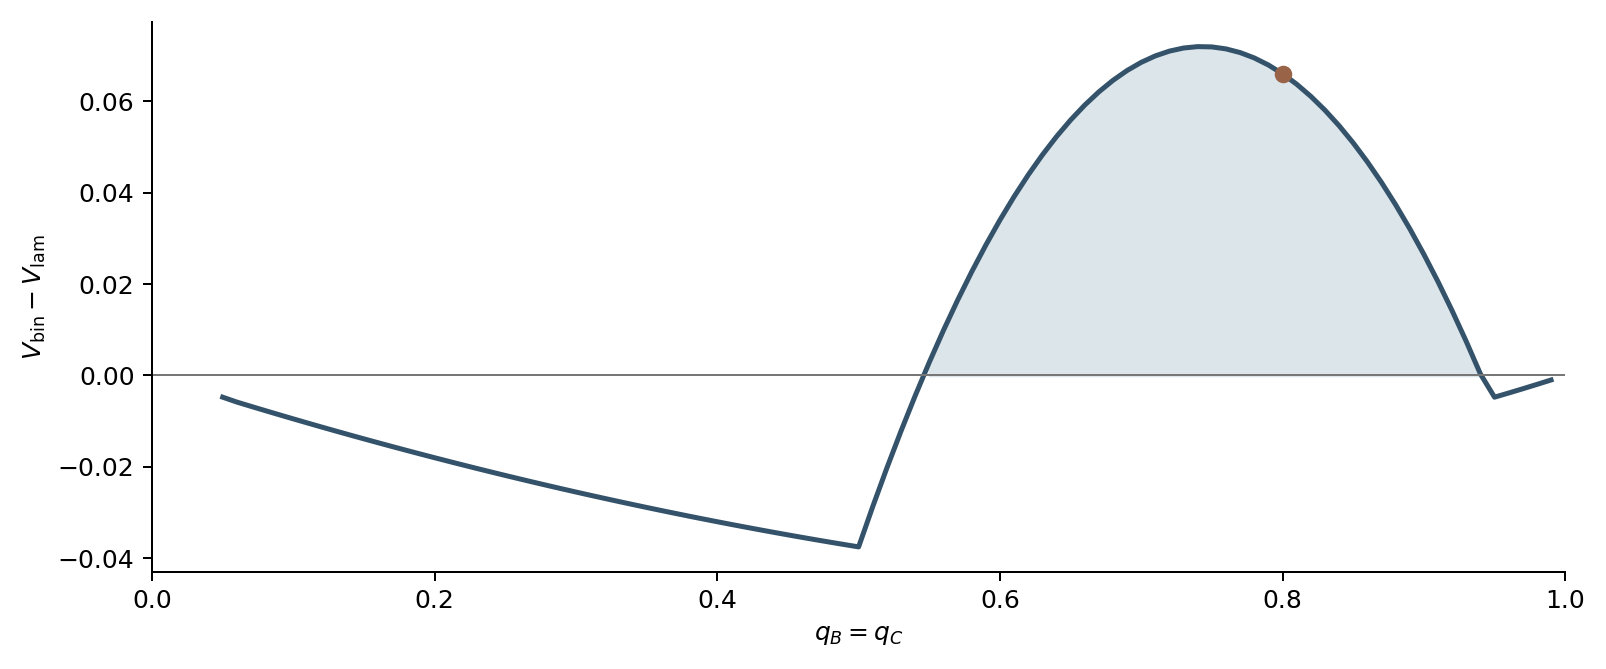

En esta malla, el binario gana en los 40 puntos de $0.55$ a $0.94$. El ejemplo presentado es $t=0.80$. Es una sección de una familia heterogénea: no describe todos los regímenes de probabilidad ni localiza fronteras continuas exactas.

La búsqueda amplia examinó 1.386 instancias exactas: 208 con binario superior, 1.142 con laminar superior y 36 empates, sin casos truncados. Incluye una malla homogénea, propuestas heterogéneas y mutaciones de buenos candidatos. Es una búsqueda dirigida, no una muestra representativa; esos porcentajes no miden cuál clase gana «normalmente».

También se encontró separación homogénea: $n=5$, $B=3$, $G=4$, $q=0.95$, $u_i=1$. Binario 4.65554625; laminar 4.6462125. El ejemplo de tres personas se eligió por su explicación más corta.

## De las cotas a una posible prueba

Para $V_{\rm aug}\le G V_{\rm bin}$, ordena $m_i=q_i u_i$ y llama $T_k$ a la suma de los $k$ mayores. Antes de probar por primera vez a una persona, su estado no influye en que la política decida incluirla: esa decisión depende de los otros estados y de la aleatoriedad independiente. Si $s_i$ es su probabilidad de aparecer, su utilidad esperada acreditada es a lo sumo $m_i s_i$. Como $\sum_i s_i\le BG$, resulta $V_{\rm aug}\le T_{BG}\le G T_B\le G V_{\rm bin}$. Se requiere independencia y priors interiores para que un sano no probado no quede acreditado por inferencia.

Para el factor cuatro: binario dinámico ≤ 2 × binario estático con pools arbitrarios ≤ 4 × binario estático disjunto ≤ 4 × aumentado laminar. [El paper de Nic, introducción y §5](https://arxiv.org/html/2601.22419v2), prueba el primer factor y atribuye el segundo a Finster et al. El último paso es inclusión de políticas.

Acercarse a $G$ requiere contabilizar las pruebas de localización. Si cubrimos $k$ grupos de tamaño $G$ y reservamos $\ell=\lceil\log_2G\rceil$ pruebas para localizar un sano, entonces $B=k+\ell$, $n=kG$, y la política laminar garantiza al menos $1-(1-q)^{kG}$. Para $q\le1/2$, el óptimo binario homogéneo es $Bq$ cuando $n\ge B$, por [Teorema 3.3](https://arxiv.org/html/2601.22419v2#S3.SS2). El cociente de esa garantía con $Bq$ tiende a $kG/(k+\ell)$ cuando $q\to0$. Después, $k\to\infty$ aproxima $G$. No es $G$ para $k$ fijo.

En la matriz de consulta, las ecuaciones son $z_A+z_B+z_C=1$, $z_A+z_B+z_D=1$, $z_A+z_C+z_D=2$, con $z_i\in\{0,1\}$. Las dos primeras dan $z_C=z_D$; la tercera obliga $z_C=z_D=1$, $z_A=0$, y entonces $z_B=0$. Son sumas enteras, no módulo dos.

Para convertir el ejemplo de matrices en una separación asintótica faltan dos piezas: una familia admisible de diseños con pocos tests y una cota para cualquier política dinámica laminar. La propuesta $V_{\rm lam}\le KB$ es una pregunta de investigación. Una cota para planes estáticos o para diagnóstico completo no la sustituye.

## Próximos pasos para discutir con Francisco

1. Revisar la construcción general del par en la nota de la proposición, con sus hipótesis y fronteras. La revisión computacional no sustituye la lectura y validación de Héctor.
2. El contraste inicial (81+20+20) está cerrado. La malla nueva tiene 32 casos, cinco contrastes laminares independientes y evaluaciones de las políticas sobre todos los perfiles de esas cinco celdas.
3. Explicar el contraejemplo de tres personas y después la familia de cuatro: ¿qué amplifica la ventaja? No sabemos si $10/9$ es una cota superior universal.
4. En $q=1/2$, $u_i=1$, estudiar la cota de información y discutir la malla ya ampliada en G. La cota $V_{\rm lam}\le KB$ y las construcciones de matrices quedan en el frente de Francisco según el plan semanal.
5. Interpretar la comparación ya calculada entre greedy, rollout, el óptimo de la jerarquía fija y el óptimo laminar por trayectoria. No son $\pi_L$ y $\pi_{\rm ratio}$; la pérdida puede incluir tanto la jerarquía elegida como la regla de decisión.

Preguntas para abrir la discusión: «¿Este ejemplo responde a la separación que buscabas?», «¿Qué parámetro debería amplificar la ventaja de volver a incluir A?», «¿Nos interesa una garantía con G fijo o independiente de G?» y «¿Qué cantidad asociada a los bloques laminares podría acotar la utilidad ganada por prueba?».

## Reproducibilidad

Desde la raíz del repositorio:

```sh
python -m augmented.experimento_sesion_29
python augmented/notebooks/build_29_sesion.py
python -m pytest augmented/tests_bellman_binario_exacto.py -q
```

Los experimentos están en `results/sesion_2026-10-12/evidencia_29.json`; la búsqueda completa, en `busqueda/cases.jsonl` y `busqueda/summary.json`. Los árboles se evaluaron independientemente sobre cada perfil, con aritmética racional. El binario se contrastó además con el solver clásico; el laminar, con el solver de átomos.

Para continuar buscando, el programa acepta una carpeta nueva y límites de tiempo:

```sh
python -m augmented.busca_binario_vs_laminar --out results/otra_busqueda --seconds 600 --random 1000 --adaptive 200
```

Es búsqueda de instancias con evaluadores fijos, semilla y registro de cada intento. No es una ejecución del agente de Karpathy ni modifica los solvers para mejorar resultados. Ese comando reproduce la primera etapa local; la ampliación posterior sí utilizó Hermeneuta. Sus registros y certificados están en `results/sesion_2026-10-12/brecha_ampliada/`.

## La familia posterior: una ventaja que se aproxima al 11.11%

$n=4$, $B=G=2$, $q=(s,1/2,1/2,s)$, $u=(1,3,3,2)$, con $19/20\le s<1$. Aquí también cambian las utilidades respecto del ejemplo de tres personas.

$$V_{\rm bin}=\frac52s(1+s),\qquad V_{\rm lam}=3+\frac32s^2.$$

La política binaria abre BD: si sale negativo prueba AC; si sale positivo prueba AD. La laminar abre BC: si el conteo es 1, prueba B; si es 0 o 2, prueba AD. La primera aprovecha la posibilidad de reutilizar D en otro grupo; la segunda combina la resolución del par BC con la oportunidad de acreditar AD.

En $s=0.99$, binario obtiene 4.92525 y laminar 4.47015. Al acercar s a 1, el cociente binario/laminar tiende a $10/9$. Es una separación alcanzable como límite, no una prueba de que ningún caso la supere. No se sustituye $s=1$: entonces A y D ya son sanos conocidos y el valor laminar cambia.

La comprobación simbólica compara todas las primeras pruebas y continuaciones mediante 454 desigualdades en el intervalo. Se reproduce con `python -m pytest augmented/tests_busqueda_brecha_ampliada.py -q`; la nota de resultados explica las ramas y enlaza el certificado. La búsqueda numérica sugirió la familia; el certificado comprueba sus fórmulas.

## El paso de información, sin identificarlo con diagnóstico completo

Sea H el historial final de una política determinista con B pruebas. Cada resultado tiene a lo sumo G+1 valores, así que hay a lo sumo $(G+1)^B$ historiales. Su entropía satisface $\mathcal H(H)\le B\log_2(G+1)$.

Con $q_i=1/2$ independiente, los $2^n$ perfiles iniciales son equiprobables. Si una hoja h es compatible con $N_h$ perfiles, su probabilidad es $N_h/2^n$. Si acredita $k_h$ sanos, esas coordenadas son cero en todos sus perfiles: $N_h\le 2^{n-k_h}$. Por tanto $k_h\le n-\log_2 N_h$.

Promediando las hojas se obtiene $E[k_H]\le n-E[\log_2 N_H]=\mathcal H(H)\le B\log_2(G+1)$. No se exige resolver a todos; se acota lo acreditado. Para una política aleatoria se fija primero su semilla independiente y luego se promedia.

Si $u_i=1$ y $B\le n$, probar B individuos da B/2 y es laminar. Así $V_{\rm aug}/V_{\rm lam}\le 2\log_2(G+1)$. Si B supera n, todos pueden probarse y los óptimos coinciden. El argumento usa q=1/2: no se traslada automáticamente a probabilidades heterogéneas.

El chequeo numérico respeta esta desigualdad en los 32 casos; no reemplaza su revisión matemática por Vlad. Tampoco demuestra que q=1/2 sea el peor régimen o que la dependencia log G sea necesaria.

## Qué se midió en Q1 y qué falta explicar

Las funciones antiguas de `laminar_benchmarks.py` cobraban solo cuando se observaba un cero. Se añadió una opción explícita `clearing="soft"`, manteniendo el comportamiento antiguo por defecto. En el control n=3, B=G=2, q=.3, rollout pasa de .6 con hard clearing a .774 con soft clearing. Esa diferencia es de convención, no evidencia de un score superior.

La jerarquía ordena personas por $q_i u_i$, agrupa bloques de tamaño hasta G y los divide en mitades. Todos sus grupos son laminares. Es solo una de las familias permitidas por el óptimo laminar por trayectoria.

Greedy maximiza la utilidad nueva inmediata; el desempate usa la máscara menor. En la malla q=.5, el individuo y el par empatan inicialmente en .5; el desempate elige individuo. Los resultados del greedy dependen de esa especificación. Un experimento siguiente útil sería cambiar solo el desempate.

Rollout evalúa una primera prueba y, en cada resultado, la continuación completa de greedy hasta agotar el presupuesto. Hace la prueba ganadora y recalcula. Su evaluación real sigue rollout después, no se compromete a usar greedy para siempre.

Para n=7, B=4, G=5: óptimo laminar 171/64; mejor política en la jerarquía fija 41/16; rollout 81/32. La pérdida total 9/64 se descompone en 7/64 por la jerarquía y 2/64 por las decisiones de rollout. Con G=4, la jerarquía y rollout sí alcanzan 171/64. Permitir G=5 no obliga a usar bloques de cinco; es nuestra construcción la que los cambia.

Comprobación: cinco celdas con óptimo laminar por átomos y por perfiles, más replay independiente de greedy y rollout. Los testigos n=7,B=4,G=3 y G=4/5 también tienen árboles o recorridos comprobados sobre sus 128 perfiles. Datos completos en `results/precio_q05_G/`.

Preguntas para Francisco: ¿conviene optimizar primero la jerarquía? ¿Cuánto cambia greedy al priorizar pares en los empates? ¿Qué decisión de rollout explica la pérdida restante aun dentro de una buena jerarquía?

## Consulta conservada

## 2. Las cotas no ordenan binario y laminar

Con independencia inicial, $0<q_i<1$ y utilidades no negativas:

$$V_{\rm bin}\le V_{\rm aug}\le G\,V_{\rm bin},\qquad
\frac14V_{\rm bin}\le V_{\rm lam}\le V_{\rm aug}.$$

El general puede reproducir una política binaria. La cota $G$ limita cuánto puede ganar al contar. La cota $1/4$ combina los dos factores dos de la comparación binaria dinámica → estática → disjunta; véase [introducción y §5 del paper de Nic](https://arxiv.org/html/2601.22419v2).

Todavía permite que el binario supere al laminar. Encontrar ese ejemplo era una pregunta de la reunión.

Para discutir: ¿cuánto puede crecer esa separación? $1/4$ es una garantía, no un ejemplo que la alcance.

Respuesta: conocemos una familia que se acerca a $V_{\rm bin}/V_{\rm lam}=10/9$ y una garantía que permite hasta 4. No sabemos cerrar esa distancia. Los dos factores dos provienen de comparaciones distintas: sus peores casos podrían no coincidir. Probaría ampliar la familia a más personas o pruebas.

## Consulta conservada

## 4. En $q=1/2$, varias ecuaciones pueden resolverlo todo

$n=4$, $B=3$, $G=3$, $q_i=1/2$, $u_i=1$.

El plan fijo ABC, ABD, ACD produce una firma distinta para cada uno de los 16 perfiles. Por ejemplo:

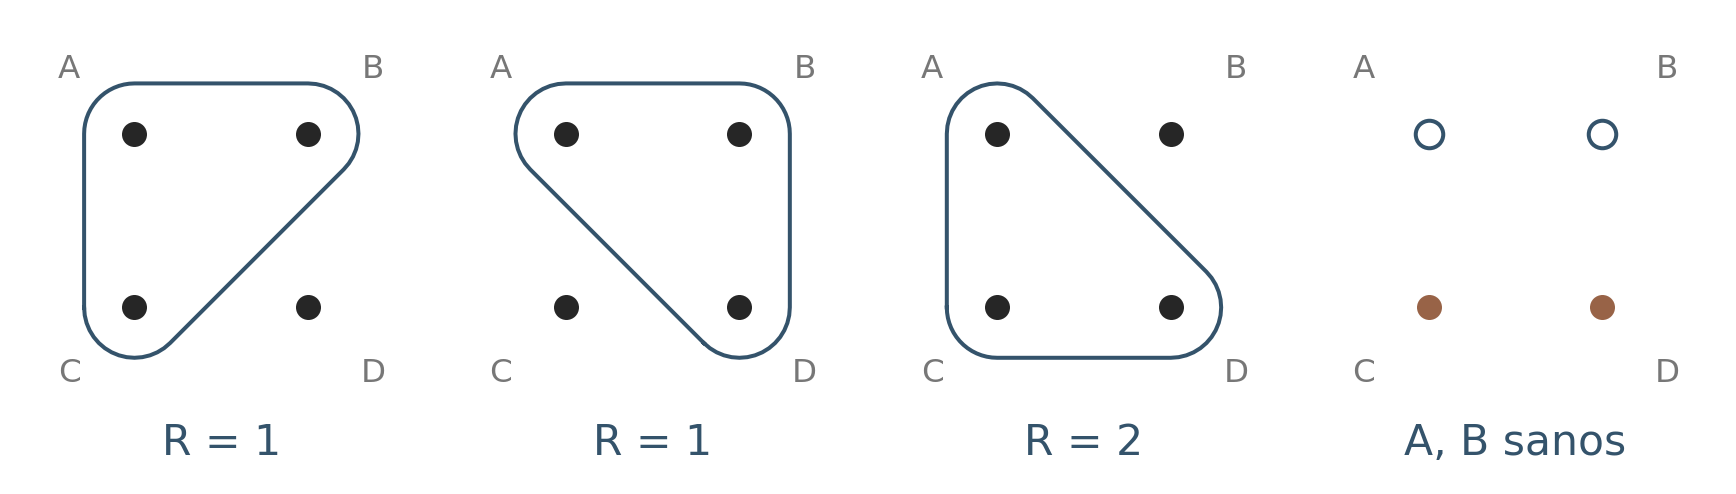

Identifica a todos con tres pruebas. Por eso alcanza toda la utilidad disponible en promedio:

$$V_{\rm bin}=1.5,\qquad V_{\rm lam}=1.75,\qquad V_{\rm aug}=n/2=2.$$

Este ejemplo retoma la ruta de matrices detectoras que propuso Francisco. Su valor es orientar una prueba: falta acotar cuánto puede obtener cualquier política dinámica laminar.

Para discutir: ¿se puede demostrar $V_{\rm lam}\le K B$ con $K$ independiente de $n,B,G$? Junto con diseños admisibles de $B=O(n/\log n)$, descartaría una garantía laminar constante independiente de $G$. Ambas piezas deben justificarse para esa conclusión.

Respuesta: es la hipótesis que intentaría probar en $q_i=1/2$, $u_i=1$. Buscaría una cantidad asociada al estado laminar que permita acotar la ganancia acumulada por prueba. No basta acotar una rama: una inferencia puede acreditar muchos sanos de golpe. Sin ese argumento, una matriz detectora eficiente todavía no demuestra una separación frente al laminar.

## Consulta conservada

## 5. Separar el costo de la restricción del costo de la regla

$\pi_L$ compara planes locales con $E[U]-0.01E[T]$; $\pi_{\rm ratio}$, con $E[U]/E[T]$. Consideran hasta tres pruebas, o las que queden, hacen la primera y vuelven a decidir.

En los tres ejemplos anteriores, ambas alcanzan el óptimo laminar. En el bloque 3, mejorar la elección dentro de la clase laminar no puede cerrar la diferencia frente al binario.

Como control homogéneo: $n=5$, $B=3$, $G=4$, $q_i=0.95$, $u_i=1$.

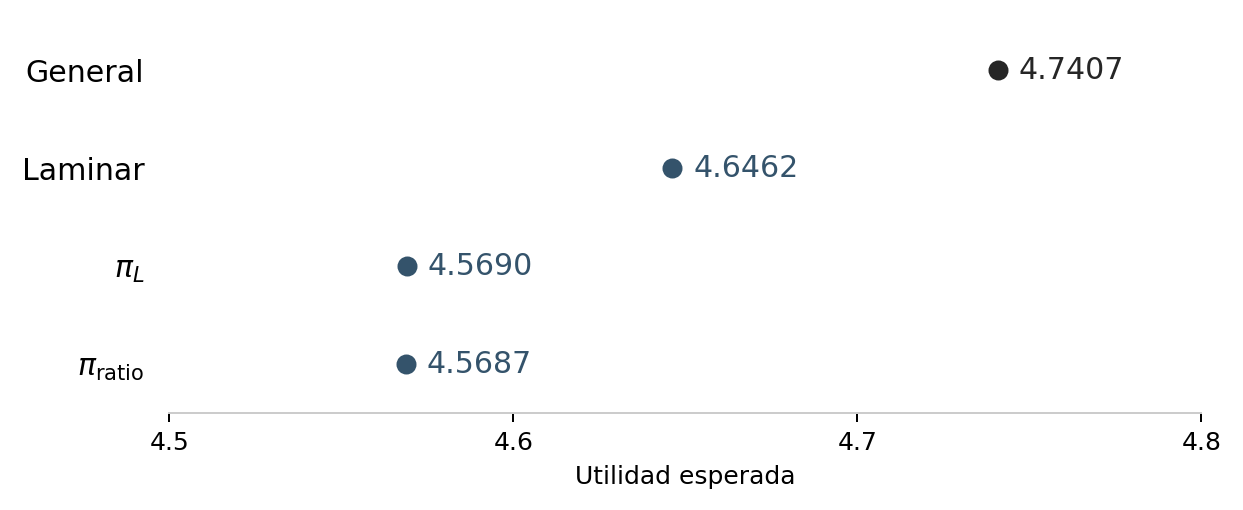

Aquí sí aparecen dos pérdidas: aproximadamente $0.0945$ por laminaridad y pérdidas adicionales de $0.07716$ con $\pi_L$ y $0.07752$ con $\pi_{\rm ratio}$. No hay evidencia en estos cuatro casos para declarar una ganadora general entre ellas.

Para discutir: ¿qué decisión explica la pérdida de las heurísticas en este control?

Respuesta: casi toda la pérdida aparece al abrir cuatro personas, mientras el óptimo laminar abre un par. Incluso continuando óptimamente tras esa apertura, obtendríamos 4.56914 frente a 4.64621. Las decisiones posteriores añaden una pérdida mucho menor. Compararía primero las aperturas con el mismo criterio de continuación; el cálculo por ramas está en las notas siguientes.

### Dónde se pierde utilidad en el control de cinco personas

Estas son $\pi_L$ y $\pi_{\rm ratio}$, distintas del greedy y rollout de la malla nueva. Ambas empiezan por ABCD; el óptimo laminar empieza por AB.

Forzar ABCD y continuar después de forma óptima da $731063/160000=4.56914375$, frente al óptimo laminar $371697/80000=4.6462125$. La apertura ya pierde $0.07706875$.

Las continuaciones añaden pérdidas pequeñas y diferentes. Si ABCD tiene dos infectados, $\pi_{\rm ratio}$ prueba E; probar AB sería mejor. Si tiene tres infectados, $\pi_L$ prueba AB; probar A sería mejor. Ponderadas por la probabilidad de llegar a esas ramas, las pérdidas adicionales son $0.00045125$ y $0.000095$, respectivamente.

La enumeración directa de las dos pruebas restantes coincide con Bellman. [Diagnóstico y fracciones](../../results/sesion_2026-10-14/diagnostico_control_29.json); reproducción: `python -m augmented.diagnostico_control_29`. Esto localiza el fallo en este control; no establece una preferencia general por abrir pares.


## Consulta: encargos y resultados anteriores

## 1. El par ya supera a individuales

$n=6$, $B=2$, $G=2$, $q_i=0.3$, $u_i=1$.

Probamos AB. Si $R=1$, probar A identifica al sano de AB. Si $R=0$ o $R=2$, dedicamos la última prueba a C.

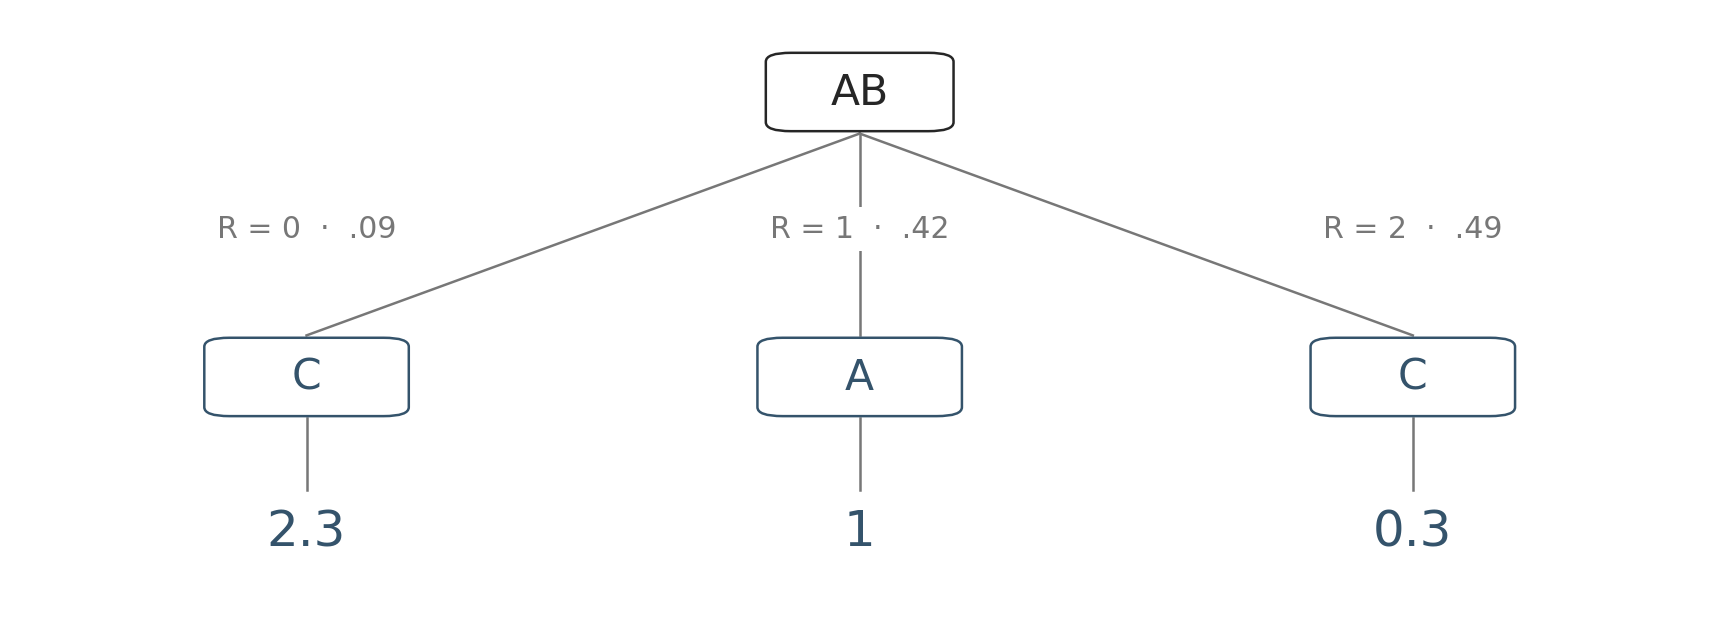

Las cifras al pie son la utilidad final esperada de cada rama, incluido lo ya cobrado.

$$V_{\rm par}=0.09(2.3)+0.42(1)+0.49(0.3)=0.774>0.6=V_{\rm individuales}.$$

La mejora viene de resolver AB con una sola prueba en las ramas extremas y aprovechar C. Es el ejemplo que quedó pendiente de enviar.

El intercambio general ya está escrito en [la nota de la proposición](../paper/proposicion_individuales_construccion.md). Para discutir: ¿qué hipótesis permiten que la ganancia sea estrictamente positiva?

Respuesta: con conteos y soft clearing, el par conserva lo que cobraríamos por A y B y libera una prueba para alguien fuera del plan de individuales. Bastan $G\ge2$, $2\le B<n$, independencia, probabilidades interiores y utilidades positivas: la ganancia es $(q_Aq_B+p_Ap_B)q_Cu_C>0$. No hace falta $q<1/2$.

## Consulta: encargos y resultados anteriores

## 2. El binario puede ganar: basta con tres personas

$n=3$, $B=2$, $G=2$, $(q_A,q_B,q_C)=(0.95,0.80,0.80)$, $u_i=1$.

Ambas políticas óptimas empiezan por AB. Si sale negativo, prueban C. Después de un positivo, el binario puede probar AC; AB y AC no forman una familia laminar.

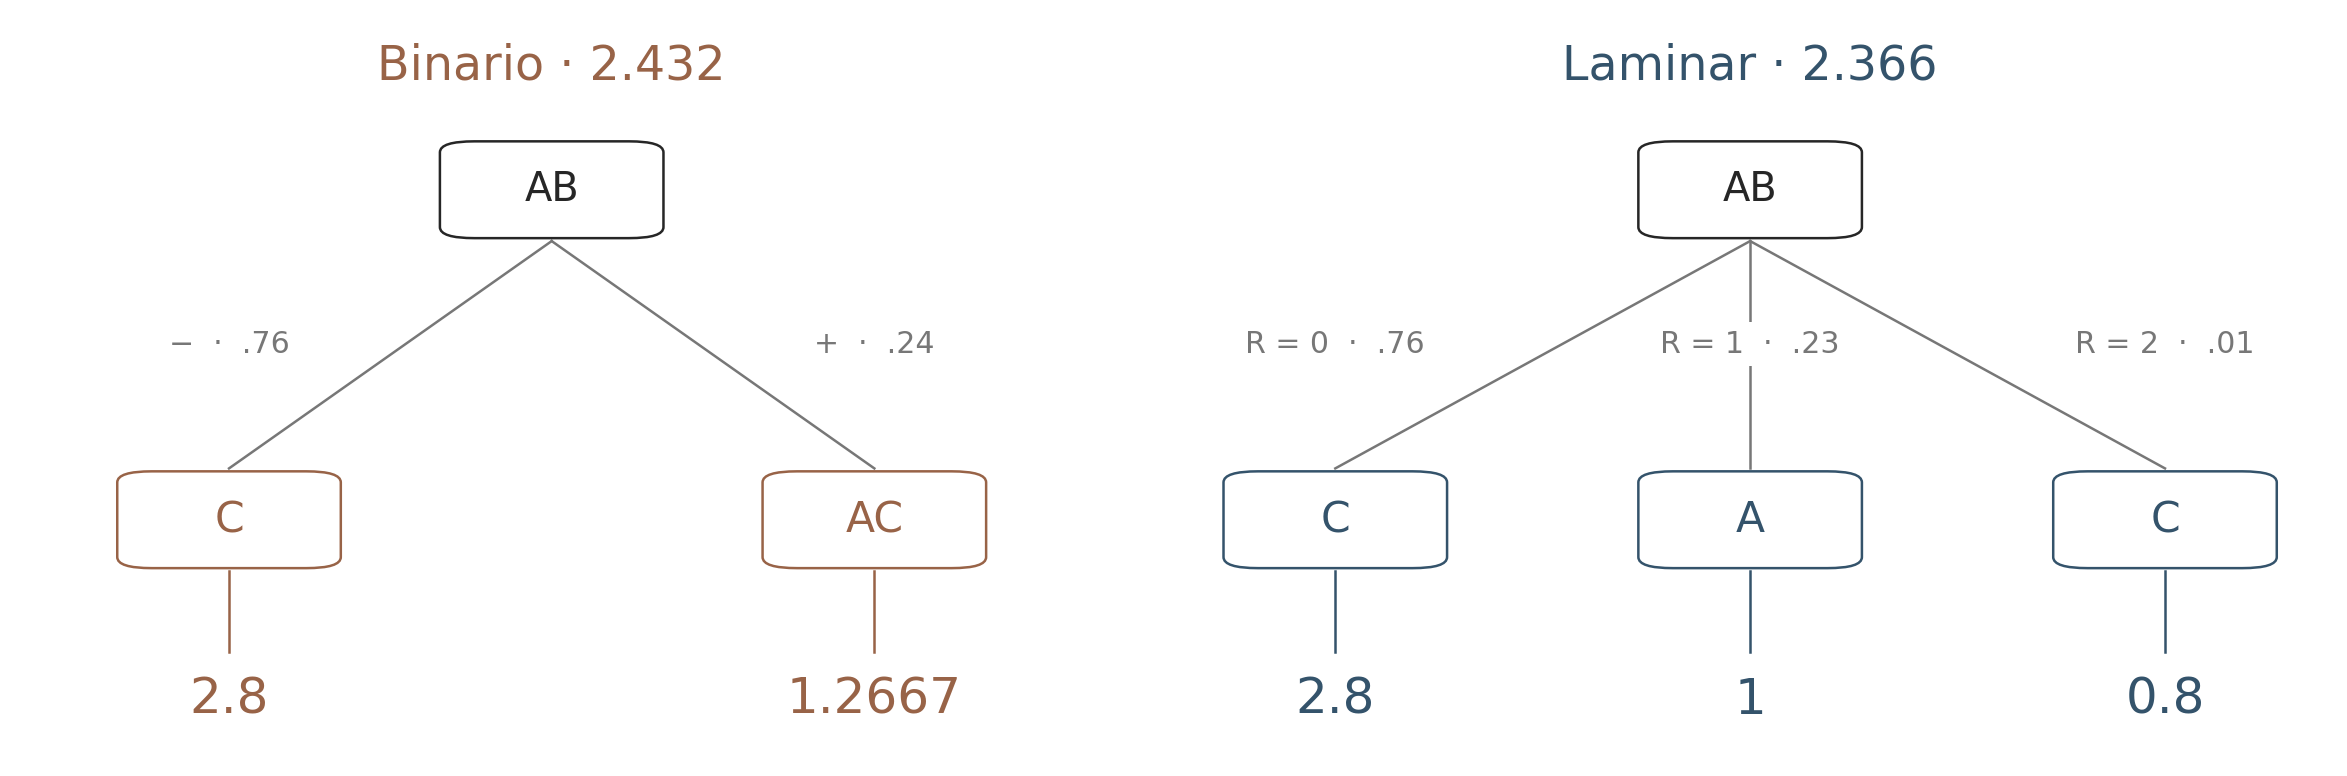

Las cifras al pie son utilidades finales esperadas condicionadas a cada rama. En la rama positiva binaria, AC sale negativo con probabilidad $19/30$: cobra 2 o cobra 0, con media $19/15\approx1.2667$.

$$V_{\rm bin}=0.76(2.8)+0.24(19/15)=2.432,$$
$$V_{\rm lam}=0.76(2.8)+0.23(1)+0.01(0.8)=2.366.$$

A sigue siendo suficientemente probable sano como para volver a incluirlo con C. Esa libertad compensa aquí la menor información del binario. El general conserva ambas ventajas y obtiene $2.448$.

Verificado sobre los 8 perfiles y todas las primeras pruebas laminares. La diferencia es $0.066$; este ejemplo demuestra existencia, no la mayor brecha posible.

La búsqueda posterior encontró una familia de cuatro personas cuya ventaja binaria se aproxima al 11.11%. La construcción y sus límites están en [los resultados actualizados](../../docs/notes/2026-10-12-encargos-6-oct.md#4-actualización-de-héctor-14-oct). Para discutir: ¿qué limita cuánto puede crecer esta ventaja?

Respuesta: todavía no sabemos el máximo. Nuestra familia se acerca a $10/9$; la cota general disponible permite hasta $4$. La libertad de volver a incluir a alguien probablemente sano explica el mecanismo, pero no fija su límite. Buscaría familias que amplifiquen esa ventaja variando probabilidades y utilidades.

## Consulta: encargos y resultados anteriores

## 3. La pérdida laminar aumenta al pasar de seis a siete personas

$n\in\{6,7\}$, $B=1,2,3,4$, $G\in\{2,3,4,5\}$, $q_i=1/2$, $u_i=1$. Son 32 casos.

Cada celda muestra $100(1-V_{\rm lam}/V_{\rm aug})$: el porcentaje de utilidad que se pierde al exigir laminaridad.

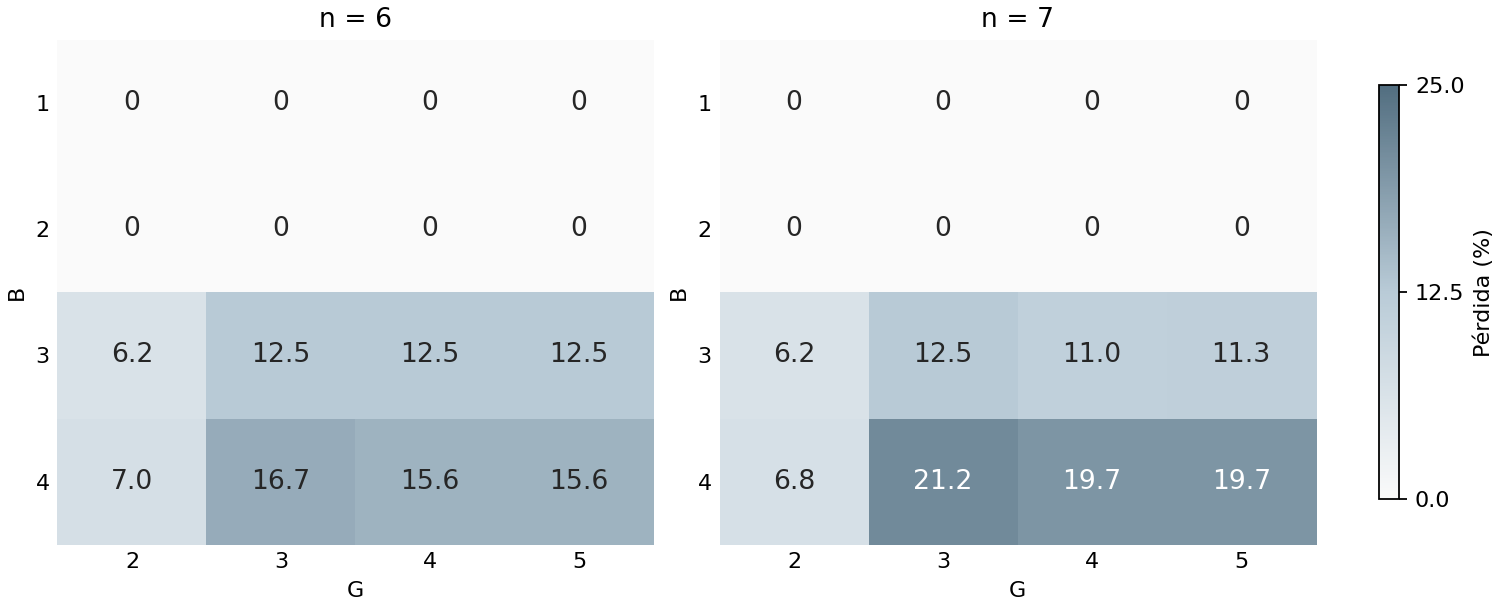

Con $B=4,G=3$, el general obtiene 3.25 y el laminar 2.5625 cuando $n=7$: una pérdida del 21.15%, frente al 16.67% con $n=6$. Con una o dos pruebas empatan en toda esta malla.

La pérdida no crece de forma monótona con $G$. Estos tamaños pequeños todavía no establecen la dependencia asintótica que busca Francisco.

## Consulta: encargos y resultados anteriores

## 4. ¿Por qué aparece log G?

$q_i=1/2$, $u_i=1$, estados independientes y $1\le B\le n$.

Una prueba de tamaño máximo $G$ tiene como mucho $G+1$ resultados. Con $B$ pruebas, la información obtenida está limitada por $B\log_2(G+1)$. Identificar a una persona sana fija uno de los bits del perfil.

El argumento da $V_{\rm aug}\le B\log_2(G+1)$. Como las individuales son laminares y obtienen $B/2$:

$$\frac{V_{\rm aug}}{V_{\rm lam}}\le 2\log_2(G+1).$$

Es el argumento que Vlad debe revisar y escribir para la proposición. Las 32 celdas respetan la cota; la demostración requiere el paso sobre información, explicado en las notas.

Para discutir: ¿qué construcción consigue una separación del mismo orden? Esa es la otra mitad de la dirección propuesta por Francisco.

Respuesta: estudiaría matrices detectoras dentro de bloques de G personas. Si resolvemos cada bloque con $O(G/\log G)$ pruebas, cobramos $G/2$ en promedio. Para obtener una brecha de orden $\log G$ falta además demostrar $V_{\rm lam}\le KB$ con K constante. Es una ruta pendiente: necesita diseños admisibles y suficientes personas y pruebas.

## Consulta: encargos y resultados anteriores

## 5. Rollout mejora las decisiones, pero la jerarquía también cuesta

Los mismos 32 casos. Greedy elige el mayor cobro inmediato; en los empates de esta malla empieza por individuales. Rollout compara cada prueba suponiendo que después seguirá greedy; ejecuta una y vuelve a comparar.

Ambos usan la misma jerarquía de grupos, fijada al inicio, y soft clearing. Cada celda muestra la mayor pérdida frente al óptimo laminar entre $n=6$ y $n=7$.

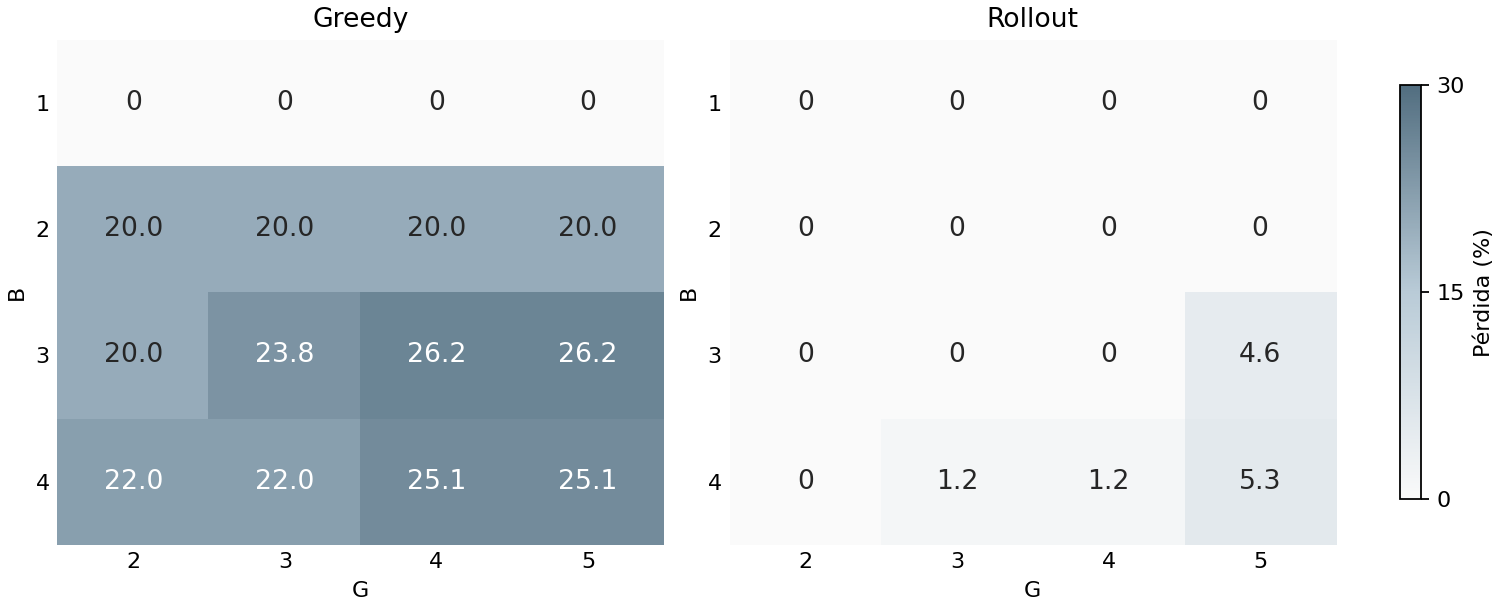

Rollout pierde como máximo 5.26% en esta malla. No toda la pérdida viene de sus decisiones: también restringimos los grupos a una jerarquía concreta.

En $n=7,B=4$, pasar de $G=4$ a $G=5$ deja el óptimo laminar en 2.671875, pero rollout baja de 2.671875 a 2.53125. La construcción automática cambia la jerarquía y empeora el resultado.

Para discutir: ¿conviene mejorar la elección de la jerarquía antes de complicar la regla de planificación?

Respuesta: en este caso empezaría por la jerarquía: explica $7/64$ de la pérdida total de $9/64$. Conservaría como opción la jerarquía de G=4, también válida con G=5. A esta escala podemos evaluar cada jerarquía completa y elegir una antes de empezar. Después mediría la pérdida restante de rollout; falta comprobar si esta prioridad se mantiene en otros casos.